In [ ]:
# Import library
import pandas as pd
import numpy as np
from tabulate import tabulate
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.cluster import KMeans
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
from tkinter import Tk
from tkinter.filedialog import askopenfilename
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Mengunggah file dataset ke Google Colab
from google.colab import files
uploaded = files.upload()

Saving Populasi_Ternak _di _Jawa_Tengah.xlsx to Populasi_Ternak _di _Jawa_Tengah.xlsx


In [ ]:
# Membaca dataset dan menentukan variabel yang digunakan dalam clustering
file_path = "Populasi_Ternak _di _Jawa_Tengah.xlsx"
data = pd.read_excel(file_path)
print(data.columns.tolist())
X = data[['Sapi Potong','Kerbau','Kuda','Kambing','Domba']]
print(X)

['Kabupaten/Kota', 'Sapi Perah', 'Sapi Potong', 'Kerbau', 'Kuda', 'Kambing', 'Domba', 'Babi']
    Sapi Potong  Kerbau  Kuda  Kambing   Domba
0         15818     365   160   158624   38583
1         13270     320    52   169153   16846
2         12425     801    61   250439   25011
3         21923     188    92   209908   54588
4         65494     221   268   103695   29088
5         16379     358    78   194223   27410
6         12790     549    29   142737   80285
7         31000    1300   125   116745  101996
8         81050     650   325    85000   49500
9         68346     373   200   110699   61598
10        20418     137    71    60978    4350
11       146233       0    27   325550   55000
12        55302      60   187    42534  113073
13        61241      27    22   115431    3825
14       151666     651    55   175498    2012
15       176447     301    79   110953    3773
16       110272      41    52    83643   13117
17        59951     415    28   229159    6221
18         34

In [ ]:
# Menghitung statistik deskriptif untuk setiap variabel populasi ternak
deskriptif = X.agg(["count", "min", "max", "mean", "median"]).transpose()
deskriptif["std"] = X.std(ddof=0).values
deskriptif = deskriptif.rename(columns={"count": "N", "min": "Minimum",
    "max": "Maximum","mean": "Mean", "median": "Median",
    "std": "Std. Deviation"}).round(2)
print(tabulate(deskriptif, headers="keys", tablefmt="fancy_grid"))

╒═════════════╤═════╤═══════════╤═══════════╤═══════════╤══════════╤══════════════════╕
│             │   N │   Minimum │   Maximum │      Mean │   Median │   Std. Deviation │
╞═════════════╪═════╪═══════════╪═══════════╪═══════════╪══════════╪══════════════════╡
│ Sapi Potong │  35 │        13 │    176447 │  36987.7  │    16379 │         45574.8  │
├─────────────┼─────┼───────────┼───────────┼───────────┼──────────┼──────────────────┤
│ Kerbau      │  35 │         0 │      5300 │    671.63 │      358 │           976.94 │
├─────────────┼─────┼───────────┼───────────┼───────────┼──────────┼──────────────────┤
│ Kuda        │  35 │         0 │       446 │     84.97 │       55 │            96.4  │
├─────────────┼─────┼───────────┼───────────┼───────────┼──────────┼──────────────────┤
│ Kambing     │  35 │       258 │    325550 │ 101972    │   103683 │         76310.8  │
├─────────────┼─────┼───────────┼───────────┼───────────┼──────────┼──────────────────┤
│ Domba       │  35 │        81 

In [21]:
# Menghitung statistik deskriptif untuk setiap variabel populasi ternak
deskriptif = X.agg(["count", "min", "max", "mean", "median"]).transpose()
# Menghitung standar deviasi populasi
deskriptif["std"] = X.std(ddof=0)
# Mengubah nama kolom dan membulatkan hasil
deskriptif = deskriptif.rename(columns={"count": "N",
    "min": "Minimum","max": "Maximum",
    "mean": "Mean","median": "Median",
    "std": "Std. Deviation"}).round(2)
# Menampilkan hasil
print(tabulate(deskriptif, headers="keys", tablefmt="fancy_grid"))

╒═════════════╤═════╤═══════════╤═══════════╤═══════════╤══════════╤══════════════════╕
│             │   N │   Minimum │   Maximum │      Mean │   Median │   Std. Deviation │
╞═════════════╪═════╪═══════════╪═══════════╪═══════════╪══════════╪══════════════════╡
│ Sapi Potong │  35 │        13 │    176447 │  36987.7  │    16379 │         45574.8  │
├─────────────┼─────┼───────────┼───────────┼───────────┼──────────┼──────────────────┤
│ Kerbau      │  35 │         0 │      5300 │    671.63 │      358 │           976.94 │
├─────────────┼─────┼───────────┼───────────┼───────────┼──────────┼──────────────────┤
│ Kuda        │  35 │         0 │       446 │     84.97 │       55 │            96.4  │
├─────────────┼─────┼───────────┼───────────┼───────────┼──────────┼──────────────────┤
│ Kambing     │  35 │       258 │    325550 │ 101972    │   103683 │         76310.8  │
├─────────────┼─────┼───────────┼───────────┼───────────┼──────────┼──────────────────┤
│ Domba       │  35 │        81 

Analisis Deskriptif Sapi Potong


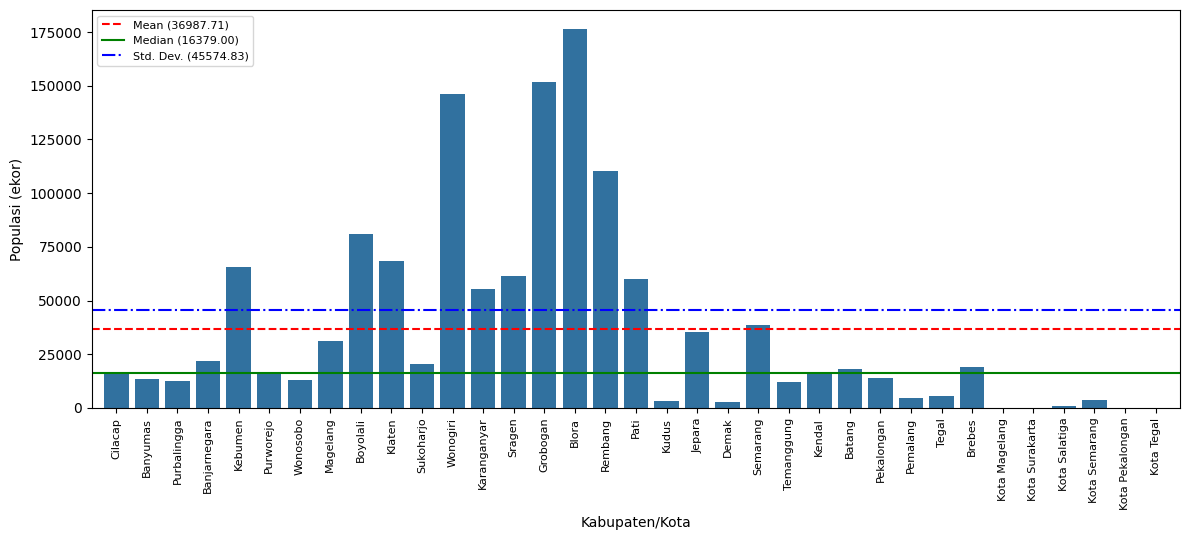

Analisis Deskriptif Kerbau


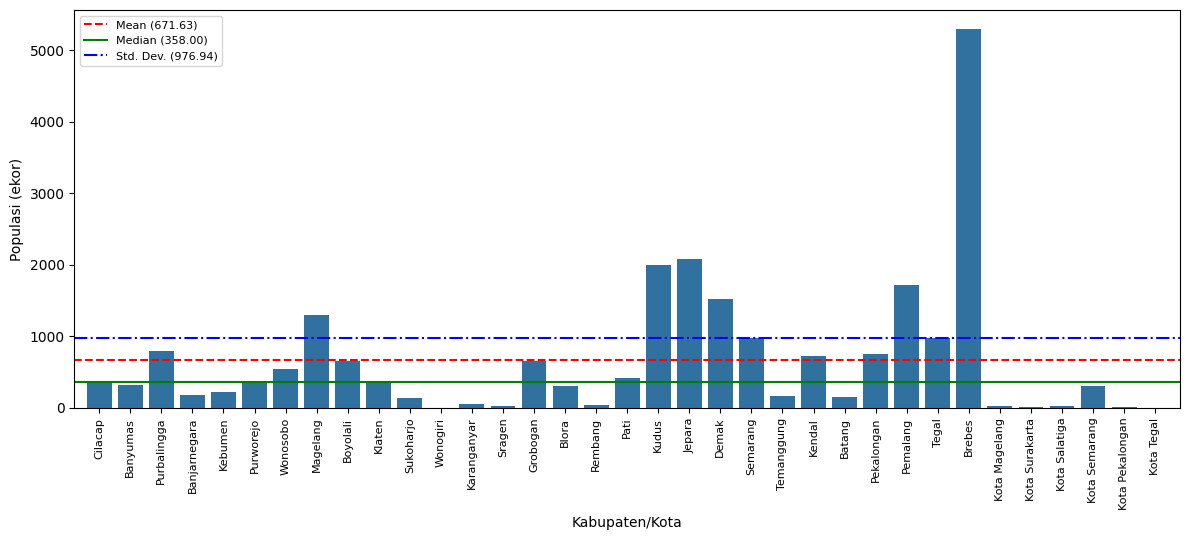

Analisis Deskriptif Kuda


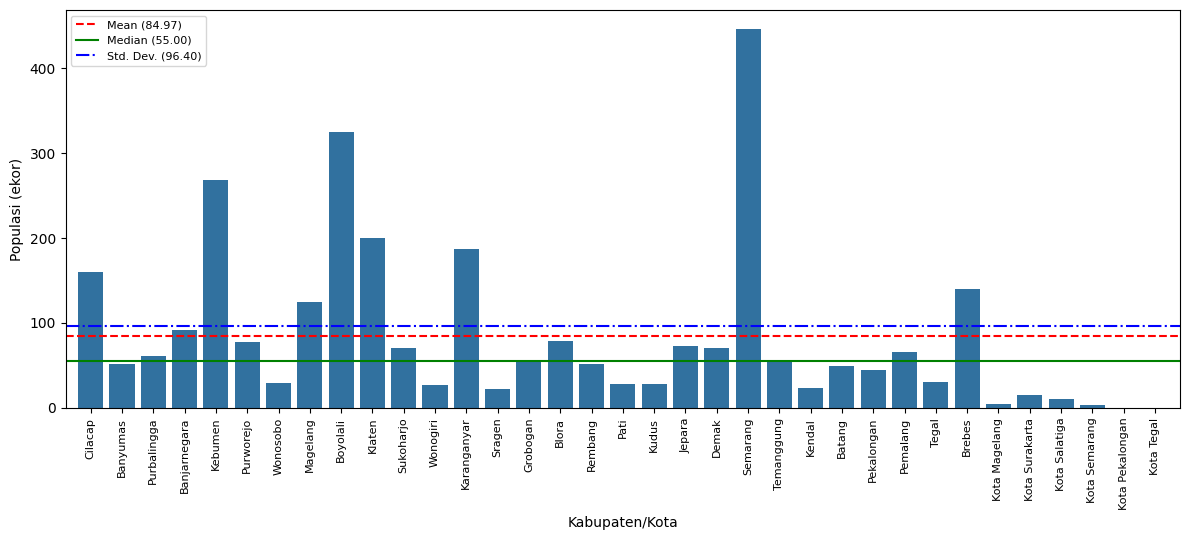

Analisis Deskriptif Kambing


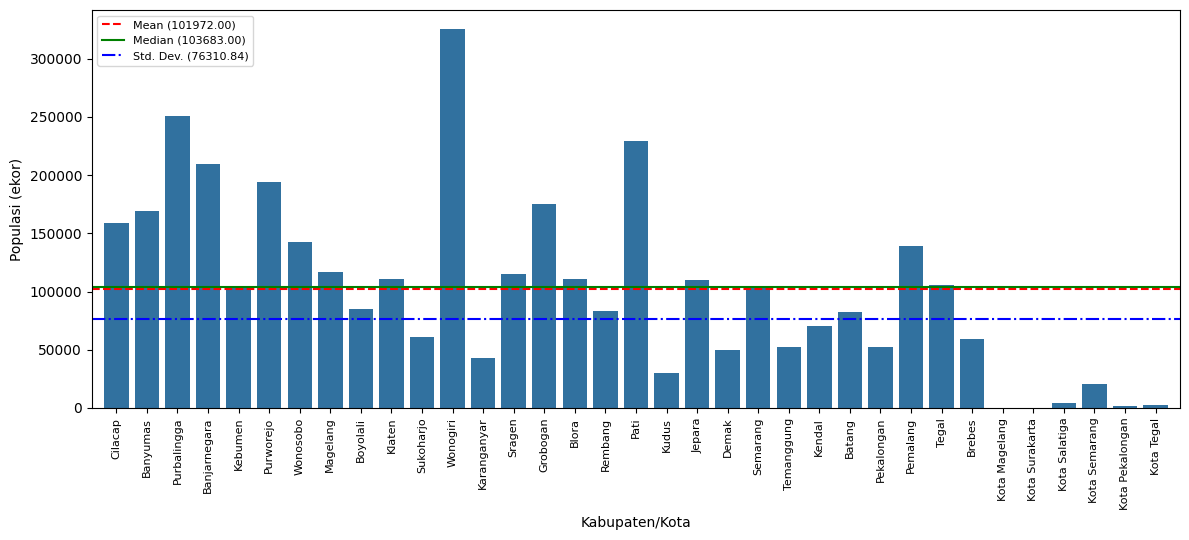

Analisis Deskriptif Domba


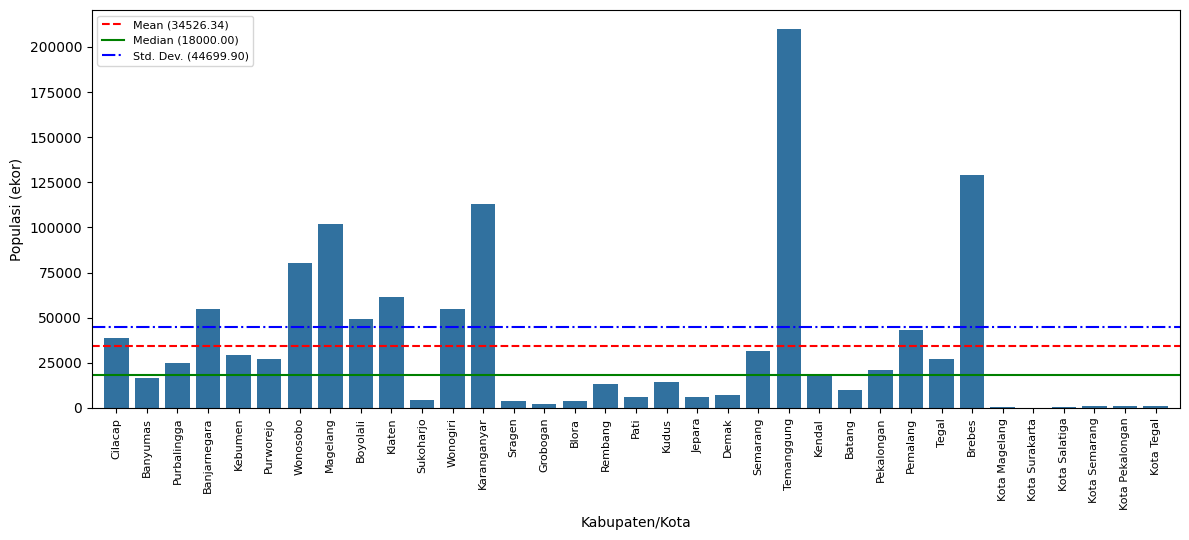

In [22]:
# Membuat diagram batang dan menampilkan nilai mean, median, standar deviasi
for i, col in enumerate(X.columns):
    rata = data[col].mean()
    med = data[col].median()
    sd = data[col].std(ddof=0)
    with plt.style.context("default"):
        fig, ax = plt.subplots(figsize=(12, 5.5))
        # Diagram batang
        ax.bar(data["Kabupaten/Kota"],
            data[col],color="#31719F")
        # Mean
        ax.axhline(rata,color="red",linestyle="--",
            label=f"Mean ({rata:.2f})")
        # Median
        ax.axhline(med,color="green",linestyle="-",
            label=f"Median ({med:.2f})")
        # Standard deviation
        ax.axhline( sd, color="blue", linestyle="-.",
            label=f"Std. Dev. ({sd:.2f})")
        print(f"Analisis Deskriptif {col}")
        ax.set_xlim(-0.8, len(data) - 0.2)
        ax.set_xlabel("Kabupaten/Kota")
        ax.set_ylabel("Populasi (ekor)")
        plt.xticks(rotation=90, fontsize=8)
        ax.legend(loc="upper left", fontsize=8)
        plt.tight_layout()
        plt.show()

In [ ]:
# Melakukan standardisasi data menggunakan Z-score
X_std = (X - X.mean()) / X.std(ddof=0)
data_std = pd.DataFrame(X_std, columns=X.columns)
data_std.insert(0, "Kabupaten/Kota", data["Kabupaten/Kota"])
display(data_std.round(4))

,Kabupaten/Kota,Sapi Potong,Kerbau,Kuda,Kambing,Domba
0,Cilacap,-0.4645,-0.3139,0.7783,0.7424,0.0908
1,Banyumas,-0.5204,-0.3599,-0.3420,0.8804,-0.3955
2,Purbalingga,-0.5390,0.1324,-0.2487,1.9456,-0.2129
3,Banjarnegara,-0.3305,-0.4950,0.0729,1.4144,0.4488
4,Kebumen,0.6255,-0.4613,1.8987,0.0226,-0.1217
5,Purworejo,-0.4522,-0.3210,-0.0723,1.2089,-0.1592
6,Wonosobo,-0.5309,-0.1255,-0.5806,0.5342,1.0237
7,Magelang,-0.1314,0.6432,0.4152,0.1936,1.5094
8,Boyolali,0.9668,-0.0221,2.4900,-0.2224,0.3350
9,Klaten,0.6881,-0.3057,1.1933,0.1144,0.6056


,K,Inertia (WCSS)
0,2,135.25156
1,3,102.10819
2,4,79.23431
3,5,59.42022


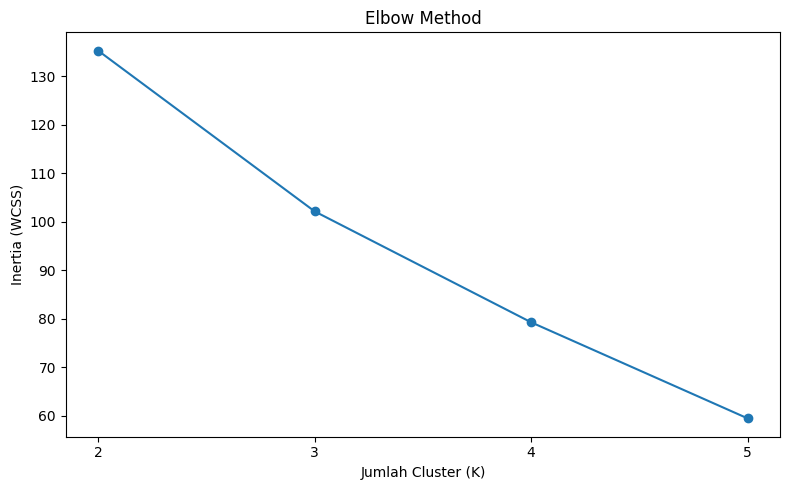

In [ ]:
# Menentukan jumlah cluster kandidat menggunakan Elbow Method
rentang_k = list(range(2, 6))
inertia = []
for k in rentang_k:
    km = KMeans(n_clusters=k,
        n_init=10,random_state=42)
    km.fit(X_std)
    inertia.append(km.inertia_)
# Menampilkan nilai Inertia (WCSS) untuk setiap jumlah cluster
tabel_elbow = pd.DataFrame({"K": rentang_k,
    "Inertia (WCSS)": np.round(inertia, 5)})
display(tabel_elbow)
# Membuat grafik Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(rentang_k, inertia,marker="o")
plt.xticks(rentang_k)
plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method")
plt.tight_layout()
plt.show()

In [ ]:
# Menetapkan jumlah cluster yang digunakan dalam proses clustering
K = 3
print("Jumlah cluster:", K)

Jumlah cluster: 3


In [ ]:
# CLUSTERING DENGAN JARAK EUCLIDEAN, MANHATTAN, DAN CHEBYSHEV
NORMA = {"Euclidean": "l2",
    "Manhattan": "l1", "Chebyshev": "linf"}
# Fungsi menghitung jarak data terhadap centroid
def hitung_jarak(X, C, norm):
    # Mengubah data menjadi array NumPy
    X = np.asarray(X, dtype=float)
    C = np.asarray(C, dtype=float)
    # Selisih setiap objek terhadap setiap centroid
    selisih = X[:, None, :] - C[None, :, :]
    if norm == "l2":
        # Euclidean Distance
        return np.sqrt(np.sum(selisih**2, axis=2))
    elif norm == "l1":
        # Manhattan Distance
        return np.sum(np.abs(selisih), axis=2)
    elif norm == "linf":
        # Chebyshev Distance
        return np.max(np.abs(selisih), axis=2)
    else:
        raise ValueError("Ukuran jarak tidak dikenal.")
# Fungsi memperbarui centroid
def perbarui_centroid(anggota, centroid_lama):
    # Jika cluster kosong, centroid lama dipertahankan
    if len(anggota) == 0:
        return centroid_lama.copy()
    # Semua centroid diperbarui menggunakan mean
    return np.mean(anggota, axis=0)
# Fungsi clustering iteratif
def kmeans_custom(X,init_centroids,
    norm="l2",max_iter=100,tol=1e-4):
    X = np.asarray(X, dtype=float)
    centroids = np.asarray(init_centroids,
        dtype=float).copy()
    K = len(centroids)
    for it in range(max_iter):
        # Menghitung jarak setiap objek terhadap seluruh centroid
        jarak_semua = hitung_jarak(X, centroids,norm)
        # Menentukan cluster dengan jarak terkecil
        labels = np.argmin(jarak_semua, axis=1)
        # Menyimpan centroid sebelum diperbarui
        centroids_lama = centroids.copy()
        # Menyiapkan centroid baru
        centroids_baru = centroids.copy()
        # Memperbarui setiap centroid menggunakan mean
        for k in range(K):
            anggota = X[labels == k]
            centroids_baru[k] = perbarui_centroid(anggota,centroids_lama[k])
        # Menghitung perubahan maksimum centroid
        perubahan = np.max(
            np.abs(centroids_baru - centroids_lama))
        # Memperbarui centroid
        centroids = centroids_baru
        # Menghentikan iterasi jika sudah konvergen
        if perubahan < tol:
            break
    # Menghitung ulang jarak menggunakan centroid akhir
    jarak_semua = hitung_jarak(X,centroids,norm)
    # Menentukan kembali cluster berdasarkan centroid akhir
    labels = np.argmin(jarak_semua,axis=1)
    # Mengambil jarak setiap objek ke centroid terpilih
    jarak = jarak_semua[np.arange(len(X)),labels]
    # Nomor cluster dimulai dari 1
    return labels + 1, centroids, jarak, it + 1
# Menentukan centroid awal
K = 3
model_awal = KMeans(n_clusters=K,
    n_init=10, random_state=42)
model_awal.fit(X_std)
init_centroids = model_awal.cluster_centers_.copy()
# Menjalankan clustering untuk setiap ukuran jarak
hasil_std = {}
for nama, norm in NORMA.items():
    labels, centroids, jarak, iterasi = kmeans_custom(X_std,
        init_centroids, norm=norm, max_iter=100, tol=1e-4)
    hasil_std[nama] = {"labels": labels,"centroids": centroids,
        "jarak": jarak,"iterasi": iterasi}
# Menyamakan nomor cluster
ukuran = np.bincount(hasil_std["Euclidean"]["labels"],
    minlength=K + 1)[1:]
urutan = np.argsort(-ukuran,kind="stable")
peta_euclidean = {int(lama) + 1: baru + 1
    for baru, lama in enumerate(urutan)}
def terapkan_peta(hasil, peta):
    # Mengubah urutan centroid tanpa mengubah koordinatnya
    centroid_baru = np.zeros_like(hasil["centroids"])
    for lama, baru in peta.items():
        centroid_baru[baru - 1] = (hasil["centroids"][lama - 1])
    # Mengubah nomor cluster
    hasil["labels"] = np.array([peta[int(label)]
        for label in hasil["labels"]])
    hasil["centroids"] = centroid_baru
# Menyamakan nomor cluster Euclidean
terapkan_peta(hasil_std["Euclidean"],peta_euclidean)
# Mencocokan cluster manhattan dan chebyshev
def peta_kecocokan(ref, lab, k):
    # Membentuk tabel kecocokan anggota cluster
    tabel = np.zeros((k, k), dtype=int)
    for a, b in zip(ref, lab):
        tabel[a - 1, b - 1] += 1
    # Mencari pasangan cluster dengan kecocokan maksimum
    baris_idx, kolom_idx = linear_sum_assignment(-tabel)
    return {int(kolom_idx[i]) + 1: int(baris_idx[i]) + 1
        for i in range(k)}
for nama in ["Manhattan", "Chebyshev"]:
    peta = peta_kecocokan(hasil_std["Euclidean"]["labels"],
        hasil_std[nama]["labels"],K)
    terapkan_peta(hasil_std[nama], peta)
# Menampilkan hasil clustering
hasil_akhir = pd.DataFrame({
    "Kabupaten/Kota": data["Kabupaten/Kota"],
    "Cluster Euclidean": hasil_std["Euclidean"]["labels"],
    "Jarak Euclidean": np.round(hasil_std["Euclidean"]["jarak"],4),
    "Cluster Manhattan": hasil_std["Manhattan"]["labels"],
    "Jarak Manhattan": np.round(hasil_std["Manhattan"]["jarak"],4),
    "Cluster Chebyshev": hasil_std["Chebyshev"]["labels"],
    "Jarak Chebyshev": np.round(hasil_std["Chebyshev"]["jarak"],4)})
print("HASIL PENGELOMPOKAN K-MEANS")
display(hasil_akhir)
# Menampilkan centroid akhir
for nama in NORMA:
    print(f"\nCENTROID AKHIR {nama.upper()}")
    tabel_centroid = pd.DataFrame(
        hasil_std[nama]["centroids"],
        columns=X.columns,index=pd.Index(
            range(1, K + 1),name="Cluster"))
    display(tabel_centroid.round(4))

HASIL PENGELOMPOKAN K-MEANS


,Kabupaten/Kota,Cluster Euclidean,Jarak Euclidean,Cluster Manhattan,Jarak Manhattan,Cluster Chebyshev,Jarak Chebyshev
0,Cilacap,1,1.5851,1,2.6676,2,0.6697
1,Banyumas,1,1.0826,1,1.6265,2,0.8545
2,Purbalingga,1,2.1305,1,2.5646,2,1.6567
3,Banjarnegara,1,1.8969,1,3.3074,2,1.1256
4,Kebumen,2,1.8101,2,2.8524,2,1.4234
5,Purworejo,1,1.4508,1,2.0530,2,0.9201
6,Wonosobo,1,1.5613,1,2.1169,2,1.0559
7,Magelang,2,1.1533,2,2.6863,2,1.0504
8,Boyolali,2,1.7013,2,2.7424,2,2.0147
9,Klaten,2,1.1909,2,2.2810,2,0.8415



CENTROID AKHIR EUCLIDEAN


,Sapi Potong,Kerbau,Kuda,Kambing,Domba
Cluster,,,,,
1,-0.5332,-0.0803,-0.4170,-0.1622,-0.3633
2,0.2055,0.4703,1.3852,-0.2336,1.2578
3,2.0170,-0.3992,-0.3815,1.0875,-0.4139



CENTROID AKHIR MANHATTAN


,Sapi Potong,Kerbau,Kuda,Kambing,Domba
Cluster,,,,,
1,-0.5338,-0.0990,-0.4115,-0.1837,-0.1768
2,0.3132,0.6104,1.6245,-0.1734,0.8767
3,2.0170,-0.3992,-0.3815,1.0875,-0.4139



CENTROID AKHIR CHEBYSHEV


,Sapi Potong,Kerbau,Kuda,Kambing,Domba
Cluster,,,,,
1,-0.5555,-0.4190,-0.6429,-0.7715,-0.6070
2,-0.1535,0.3558,0.4753,0.2888,0.4590
3,2.3953,-0.4334,-0.3291,0.9427,-0.3591


In [ ]:
# Menghitung jumlah anggota tiap cluster untuk masing-masing ukuran jarak
count_euclidean = hasil_akhir["Cluster Euclidean"].value_counts().sort_index()
count_manhattan = hasil_akhir["Cluster Manhattan"].value_counts().sort_index()
count_chebyshev = hasil_akhir["Cluster Chebyshev"].value_counts().sort_index()
# Menggabungkan jumlah anggota ke satu tabel
cluster_counts = pd.DataFrame({"Euclidean": count_euclidean,
    "Manhattan": count_manhattan,"Chebyshev": count_chebyshev
    }).fillna(0).astype(int)
print("\nJumlah Anggota Cluster per Ukuran Jarak")
display(cluster_counts)


Jumlah Anggota Cluster per Ukuran Jarak


,Euclidean,Manhattan,Chebyshev
1,22,23,12
2,8,7,19
3,5,5,4


In [ ]:
# Menentukan karakteristik setiap cluster berdasarkan rata-rata data asli
# Fitur yang digunakan dalam clustering
features_for_char = X.columns.tolist()
# Salin data asli untuk menghitung karakteristik cluster
df_original = data[features_for_char].copy()
# Tambahkan label cluster dari hasil clustering
df_original["Cluster Euclidean"] = hasil_akhir["Cluster Euclidean"]
df_original["Cluster Manhattan"] = hasil_akhir["Cluster Manhattan"]
df_original["Cluster Chebyshev"] = hasil_akhir["Cluster Chebyshev"]
# Hitung rata-rata data asli per cluster
char_euclidean = (df_original.groupby("Cluster Euclidean")[features_for_char]
    .mean().round(2).reset_index())
char_manhattan = (df_original.groupby("Cluster Manhattan")[features_for_char]
    .mean().round(2).reset_index())
char_chebyshev = (df_original.groupby("Cluster Chebyshev")[features_for_char]
    .mean().round(2).reset_index())
# Menampilkan karakteristik masing-masing cluster
print("Karakteristik Cluster Euclidean (Data Asli)")
display(char_euclidean)
print("Karakteristik Cluster Manhattan (Data Asli)")
display(char_manhattan)
print("Karakteristik Cluster Chebyshev (Data Asli)")
display(char_chebyshev)

Karakteristik Cluster Euclidean (Data Asli)


,Cluster Euclidean,Sapi Potong,Kerbau,Kuda,Kambing,Domba
0,1,12689.09,593.18,44.77,89594.00,18286.14
1,2,46355.12,1131.12,218.50,84143.62,90750.50
2,3,128913.80,281.60,48.20,184960.60,16024.60


Karakteristik Cluster Manhattan (Data Asli)


,Cluster Manhattan,Sapi Potong,Kerbau,Kuda,Kambing,Domba
0,1,12659.13,574.91,45.30,87957.30,26621.52
1,2,51263.00,1268.00,241.57,88742.71,73714.86
2,3,128913.80,281.60,48.20,184960.60,16024.60


Karakteristik Cluster Chebyshev (Data Asli)


,Cluster Chebyshev,Sapi Potong,Kerbau,Kuda,Kambing,Domba
0,1,11672.92,262.33,23.00,43096.83,7394.50
1,2,29993.53,1019.26,130.79,124011.26,55041.37
2,3,146154.50,248.25,53.25,173911.00,18475.50


In [ ]:
# Menghitung Silhouette Coefficient untuk masing-masing ukuran jarak
hasil_silhouette = {}
for nama, metric in [("Euclidean", "euclidean"),
    ("Manhattan", "manhattan"), ("Chebyshev", "chebyshev")]:
    labels = hasil_std[nama]["labels"]
    # Menghitung nilai silhouette setiap data
    nilai_silhouette = silhouette_samples(
        X_std, labels, metric=metric)
    # Menghitung rata-rata silhouette setiap cluster
    rata_cluster = []
    for cluster in range(1, K + 1):
        rata = nilai_silhouette[labels == cluster].mean()
        rata_cluster.append(rata)
    # Menghitung rata-rata silhouette keseluruhan
    rata_total = silhouette_score(
        X_std, labels, metric=metric)
    hasil_silhouette[nama] = rata_cluster + [rata_total]
# Membuat tabel hasil Silhouette Coefficient
silhouette_result = pd.DataFrame( hasil_silhouette,
    index=["Cluster 1", "Cluster 2", "Cluster 3", "Rata-rata"])
# Menampilkan tabel
display(silhouette_result.style.format(
        "{:.4f}", decimal=",").set_table_styles([
        {"selector": "th", "props": [("text-align", "center")]},
        {"selector": "td", "props": [("text-align", "center")]}]))

,Euclidean,Manhattan,Chebyshev
Cluster 1,"0,4484","0,3745","0,6774"
Cluster 2,"0,0693","0,1694","-0,0119"
Cluster 3,"0,2745","0,2776","0,3352"
Rata-rata,"0,3369","0,3197","0,2641"


In [ ]:
# Mengunggah file ZIP peta dan mengekstrak isinya untuk pembuatan peta
from google.colab import files
import zipfile
import os
uploaded_peta = files.upload()
nama_zip = list(uploaded_peta.keys())[0]
print("File ZIP terbaca:", nama_zip)
with zipfile.ZipFile(nama_zip, "r") as z:z.extractall(".")

Saving gadm41_IDN_2.json.zip to gadm41_IDN_2.json.zip
File ZIP terbaca: gadm41_IDN_2.json.zip


In [ ]:
# Membaca file GeoJSON atau JSON dan menyiapkan data fitur wilayah untuk pembuatan peta
import json
import zipfile
def muat_geojson(nama):
    if nama.lower().endswith(('.geojson', '.json')):
        with open(nama, 'r', encoding='utf-8') as f:
            return json.load(f)
    if nama.lower().endswith('.zip'):
        with zipfile.ZipFile(nama, 'r') as z:
            daftar_file = z.namelist()
            file_geojson = next(
                (f for f in daftar_file
                    if f.lower().endswith(
                        ('.geojson', '.json'))), None)
            if file_geojson is None:
                raise ValueError(
                    'Tidak ditemukan file .geojson atau .json di dalam ZIP.')
            with z.open(file_geojson) as f:
                return json.load(f)
    raise ValueError(
        'Format tidak dikenali. Gunakan .geojson, .json, '
        'atau .zip berisi GeoJSON.')
# Membaca file peta
geo = muat_geojson(nama_zip)
if geo.get('type') == 'Topology':
    raise ValueError('File berformat TopoJSON. Gunakan GeoJSON.')
fitur = (geo['features']
    if geo.get('type') == 'FeatureCollection'
    else [geo])
print( "Jumlah fitur (poligon wilayah) di file peta:", len(fitur))
print('Contoh properti fitur pertama:', fitur[0]['properties'])

Jumlah fitur (poligon wilayah) di file peta: 502
Contoh properti fitur pertama: {'GID_2': 'IDN.1.2_1', 'GID_0': 'IDN', 'COUNTRY': 'Indonesia', 'GID_1': 'IDN.1_1', 'NAME_1': 'Aceh', 'NL_NAME_1': 'NA', 'NAME_2': 'AcehBarat', 'VARNAME_2': 'NA', 'NL_NAME_2': 'NA', 'TYPE_2': 'Kabupaten', 'ENGTYPE_2': 'Regency', 'CC_2': '1107', 'HASC_2': 'ID.AC.AB'}


In [ ]:
# Menentukan pengaturan nama wilayah pada peta
import re
KOLOM_NAMA_PETA = None
MANUAL_NAMA = {}
def huruf_saja(teks):
    return re.sub(r"[^a-z]", "", str(teks).lower())
def kunci_wilayah(nama, tipe=None):
    h = huruf_saja(nama)
    t = huruf_saja(tipe) if tipe is not None else ""
    is_kota = (h.startswith("kota")or "kota" in t or "city" in t)
    for awalan in ("kabupaten", "kab", "kota"):
        if h.startswith(awalan):
            h = h[len(awalan):]
            break
    return is_kota, h
def poligon_geom(geom):
    if not geom:
        return []
    if geom["type"] == "Polygon":
        return [geom["coordinates"]]
    if geom["type"] == "MultiPolygon":
        return geom["coordinates"]
    if geom["type"] == "GeometryCollection":
        hasil = []
        for g in geom.get("geometries", []):
            hasil.extend(poligon_geom(g))
        return hasil
    return []
def luas_ring(ring):
    ring = np.asarray(ring)[:, :2]
    x = ring[:, 0]
    y = ring[:, 1]
    return 0.5 * abs(np.sum(x[:-1] * y[1:] - x[1:] * y[:-1]))
def luas_fitur(fitur_satu):
    total = 0.0
    for poli in poligon_geom(
        fitur_satu["geometry"]):
        cincin = [np.asarray(ring)[:, :2]
            for ring in poli]
        if not cincin:
            continue
        total += luas_ring(cincin[0])
        for lubang in cincin[1:]:
            total -= luas_ring(lubang)
    return total
# Membersihkan fitur peta dan mengambil wilayah Jawa Tengah
n_awal = len(fitur)
fitur = [f for f in fitur
    if f.get("geometry")
    and poligon_geom(f["geometry"])]
if len(fitur) < n_awal:
    print(f"{n_awal - len(fitur)} fitur tanpa geometri dibuang")
prop_string = sorted({k
    for f in fitur
    for k, v in f.get("properties", {}).items()
    if isinstance(v, str)})
for p in prop_string:
    nilai_p = [huruf_saja(f.get("properties", {}).get(p, ""))
        for f in fitur]
    if "jawatengah" in nilai_p:
        fitur = [f
            for f, v in zip(fitur, nilai_p)
            if v == "jawatengah"]
        print(f"Filter provinsi memakai properti "
            f"'{p}': {len(fitur)} fitur Jawa Tengah")
        break
# Menentukan kolom nama wilayah pada peta
kunci_data = {kunci_wilayah(nama): nama
    for nama in data["Kabupaten/Kota"]}
inti_data = {kunci[1]
    for kunci in kunci_data}
skor = {}
for p in prop_string:
    skor[p] = sum(
        kunci_wilayah(f.get("properties", {}).get(p, ""))[1] in inti_data
        for f in fitur)
if KOLOM_NAMA_PETA is not None:
    if KOLOM_NAMA_PETA not in prop_string:
        raise ValueError(f"Kolom '{KOLOM_NAMA_PETA}' tidak ditemukan. "
            f"Kolom yang tersedia: {prop_string}")
    prop_nama = KOLOM_NAMA_PETA
else:
    prop_nama = max(skor,key=skor.get)
if skor.get(prop_nama, 0) == 0:
    raise ValueError(
        "Tidak ada kolom di file peta yang cocok ""dengan nama wilayah.\n"
        "Isi KOLOM_NAMA_PETA secara manual.\n"
        f"Kolom yang tersedia: {prop_string}")
print("Kolom nama wilayah di peta:",prop_nama)
# Menentukan kolom tipe Kabupaten/Kota
prop_tipe = None
for p in prop_string:
    if p == prop_nama:
        continue
    nilai_p = {huruf_saja(f.get("properties", {}).get(p, ""))
        for f in fitur}
    nilai_p = {v for v in nilai_p
        if v}
    ada_kota = any("kota" in v or "city" in v
        for v in nilai_p)
    ada_kabupaten = any("kab" in v
        or "regency" in v
        or "kabupaten" in v
        for v in nilai_p)
    if ada_kota and ada_kabupaten:
        prop_tipe = p
        break
print("Kolom tipe (Kabupaten/Kota):", prop_tipe)
# Membuat kunci wilayah dan menangani nama wilayah yang sama
kunci_fitur = []
for f in fitur:
    properti = f.get("properties", {})
    nama = properti.get(prop_nama,"")
    tipe = (properti.get(prop_tipe, "")
        if prop_tipe
        else None)
    is_kota, inti = kunci_wilayah(nama, tipe)
    kunci_fitur.append([is_kota, inti])
grup = {}
for i, (_, inti) in enumerate(kunci_fitur):
    if inti:
        grup.setdefault(inti,[]).append(i)
for inti, indeks in grup.items():
    if len(indeks) != 2:
        continue
    if any( kunci_fitur[i][0]
        for i in indeks):
        continue
    indeks_kota = min(indeks,key=lambda i: luas_fitur(fitur[i]))
    kunci_fitur[indeks_kota][0] = True
# Mencocokkan data dengan wilayah pada peta
indeks_peta = {}
for i, (is_kota, inti) in enumerate(
    kunci_fitur):
    kunci = (bool(is_kota),inti)
    if kunci in kunci_data:
        nama_data = kunci_data[kunci]
        indeks_peta[nama_data] = i
# Melakukan pencocokan cadangan dan koreksi manual
terpakai = set(indeks_peta.values())
for ((is_kota_data, inti_data_wilayah),nama_data) in kunci_data.items():
    if nama_data in indeks_peta:
        continue
    kandidat = [i
        for i, (_, inti_peta) in enumerate(kunci_fitur)
        if inti_peta == inti_data_wilayah
        and i not in terpakai]
    if len(kandidat) == 1:
        indeks_peta[nama_data] = kandidat[0]
        terpakai.add(kandidat[0])
        print(f"Dicocokkan lewat nama inti saja: "
              f"{nama_data}")
for nama_data, nama_peta_manual in MANUAL_NAMA.items():
    for i, f in enumerate(fitur):
        nama_peta = f.get("properties", {}).get(prop_nama,"")
        if nama_peta == nama_peta_manual:
            indeks_peta[nama_data] = i
            break
# Memeriksa hasil pencocokan wilayah
belum = [nama
    for nama in data["Kabupaten/Kota"]
    if nama not in indeks_peta]
print(f"\nWilayah yang cocok dengan peta: "
    f"{len(indeks_peta)} dari {len(data)}")
if belum:
    print("\nWilayah yang belum cocok:")
    for nama in belum:
        print(f"- {nama}")
    print("\nNama wilayah di file peta:")
    nama_peta = sorted(str(f.get("properties", {}).get(prop_nama, ""))
        for f in fitur)
    for nama in nama_peta:
        print(f"- {nama}")
else:
    print("Semua wilayah berhasil dicocokkan.")

Filter provinsi memakai properti 'NAME_1': 36 fitur Jawa Tengah
Kolom nama wilayah di peta: NAME_2
Kolom tipe (Kabupaten/Kota): ENGTYPE_2

Wilayah yang cocok dengan peta: 35 dari 35
Semua wilayah berhasil dicocokkan.


In [ ]:
from matplotlib.path import Path
from matplotlib.patches import PathPatch
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
# Pengaturan tampilan peta
GAYA_PETA = "abu"
UKURAN_LABEL = 8
WARNA_GARIS = "black"
TEBAL_GARIS = 0.5
UKURAN_MIN = 6
UKURAN_LUAR = 7
LABEL_TIPE = "ganda"
# Ukuran disesuaikan dengan gambar contoh
UKURAN_PETA = (9, 6)
RESOLUSI_PETA = 150
FONT_PETA = {"font.family": "serif",
    "font.serif": ["Times New Roman","Liberation Serif",
                   "Nimbus Roman", "DejaVu Serif"]}
# Membuat bentuk poligon
def path_poligon(poli):
    """Membuat Path matplotlib untuk satu poligon."""
    verts = []
    kode = []
    for ring in poli:
        arr = np.array(ring)[:, :2]
        if len(arr) < 3:
            continue
        verts.extend(arr.tolist())
        kode.extend(
            [Path.MOVETO]
            + [Path.LINETO] * (len(arr) - 2)
            + [Path.CLOSEPOLY])
    return Path(verts, kode)
def poligon_utama(geom):
    """Mengambil poligon terbesar dari suatu wilayah."""
    return max(
        poligon_geom(geom),
        key=lambda p: luas_ring(np.array(p[0])[:, :2]))
def titik_dalam(geom, n_grid=35):
    """Mencari titik di dalam wilayah untuk menempatkan label."""
    utama = poligon_utama(geom)
    luar = np.array(utama[0])[:, :2]
    xmin, ymin = luar.min(axis=0)
    xmax, ymax = luar.max(axis=0)
    gx, gy = np.meshgrid(np.linspace(xmin, xmax, n_grid),
        np.linspace(ymin, ymax, n_grid))
    titik = np.column_stack([gx.ravel(), gy.ravel()])
    dalam = Path(luar).contains_points(titik)
    for lubang in utama[1:]:
        dalam &= ~Path(
            np.array(lubang)[:, :2]).contains_points(titik)
    if not dalam.any():
        return luar.mean(axis=0)
    kandidat = titik[dalam]
    if len(luar) <= 1500:
        batas = luar
    else:
        batas = luar[::len(luar) // 1500 + 1]
    jarak = np.sqrt(((kandidat[:, None, :] - batas[None, :, :]) ** 2
        ).sum(axis=2)).min(axis=1)
    return kandidat[np.argmax(jarak)]
# Menentukan tingkat cluster
def peringkat_tingkat(label):
    """Menentukan tingkat cluster (0 rendah, 1 menengah, 2 tinggi)
    secara konsisten untuk ketiga ukuran jarak."""
    rata_z = hasil_std[label]["centroids"].mean(axis=1)
    assert rata_z.argmin() == 0, (
        f"Cluster 1 bukan yang terendah pada {label}, "
        "periksa penomoran cluster")
    return np.array([TINGKAT_CLUSTER[c] for c in range(1, K + 1)])
def warna_peta(label):
    """Menentukan warna setiap cluster."""
    if GAYA_PETA == "warna":
        return {c: tuple(warna_cluster[c - 1][:3])
            for c in range(1, K + 1)}
    peringkat = peringkat_tingkat(label)
    if K == 1:
        abu = [0.6]
    elif K == 3:
        abu = [1.0, 0.6, 0.0]
    else:
        abu = list(np.linspace(1.0, 0.0, K))
    return {c: (abu[peringkat[c - 1]],) * 3
        for c in range(1, K + 1)}
# Membuat kompas arah mata angin
def gambar_kompas(ax_utama,
    posisi=(0.80, 0.68, 0.18, 0.28)):
    """Membuat kompas arah mata angin."""
    ak = ax_utama.inset_axes(list(posisi))
    ak.set_xlim(-1.4, 1.4)
    ak.set_ylim(-1.4, 1.4)
    ak.set_aspect("equal")
    ak.axis("off")
    ak.add_patch(
        plt.Circle((0, 0), 0.62,
            fill=False, lw=1.0, ec="black"))
    ak.add_patch(
        plt.Circle((0, 0), 0.50,
            fill=False, lw=0.6, ec="black"))
    lengan = ([(s, 0.55, 0.10, "gray")
         for s in (45, 135, 225, 315)] +
        [(s, 1.0, 0.15, "black")
         for s in (0, 90, 180, 270)])
    for sudut, panjang, lebar, wr in lengan:
        t = np.radians(sudut)
        ujung = np.array([
            np.cos(t), np.sin(t)]) * panjang
        samping = np.array([
            -np.sin(t), np.cos(t)]) * lebar
        ak.add_patch(
            plt.Polygon([ujung, samping, -samping],
                closed=True, fc=wr, ec="black", lw=0.6))
    arah = {"N": (0, 1.25), "E": (1.25, 0),
        "S": (0, -1.25), "W": (-1.25, 0)}
    for teks, (x, y) in arah.items():
        ak.text(x, y, teks, ha="center",
            va="center", fontsize=8)
# Mengatur label nama wilayah
def teks_label_peta(daftar_nama):
    """Membuat teks label wilayah."""
    inti = {n: re.sub(r"^(Kab\.|Kota)\s*", "", n)
        for n in daftar_nama}
    tipe = {n: n.startswith("Kota")
        for n in daftar_nama}
    jenis = {}
    for n in daftar_nama:
        jenis.setdefault(
            inti[n].lower(), set()
        ).add(tipe[n])
    hasil = {}
    for n in daftar_nama:
        kembar = (
            len(jenis[inti[n].lower()]) == 2)
        if (LABEL_TIPE == "semua"
            or (LABEL_TIPE == "ganda" and kembar)):
            hasil[n] = (
                inti[n]
                + "\n"
                + ("Kota" if tipe[n] else "Kab."))
        else:
            hasil[n] = inti[n]
    return hasil
# Menempatkan label wilayah
def pasang_label_peta(
    fig, ax, klaster, warna, teks_wilayah):
    """Menempatkan label wilayah agar tidak bertumpuk."""
    try:
        rend = fig.canvas.get_renderer()
    except AttributeError:
        rend = fig._get_renderer()
    transform = ax.transData.transform
    sx = (transform((1, 0))[0] - transform((0, 0))[0])
    sy = (transform((0, 1))[1] - transform((0, 0))[1])
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()
    def ke_data(bb):
        (a, b), (c, d) = (ax.transData.inverted().transform(
                [[bb.x0, bb.y0], [bb.x1, bb.y1]]))
        return a, b, c, d
    info = {}
    for nama, i in indeks_peta.items():
        utama = poligon_utama(
            fitur[i]["geometry"])
        luar = np.array(utama[0])[:, :2]
        info[nama] = {
            "luar": Path(luar),
            "lubang": [Path(np.array(l)[:, :2])
                for l in utama[1:]],
            "bb": (*luar.min(axis=0),
                *luar.max(axis=0)),
            "xy": titik_dalam(
                fitur[i]["geometry"])}
    semua_darat = [v["luar"] for v in info.values()]
    def titik_kotak(cx, cy, w, h, nx=5, ny=3):
        gx, gy = np.meshgrid(
            np.linspace(cx - w / 2, cx + w / 2, nx),
            np.linspace(cy - h / 2, cy + h / 2, ny))
        return np.column_stack([
            gx.ravel(),
            gy.ravel()])
    def muat_di_dalam(v, cx, cy, w, h):
        pts = titik_kotak(cx, cy, w, h)
        masuk = v["luar"].contains_points(pts).all()
        tidak_di_lubang = not any(
            lubang.contains_points(pts).any()
            for lubang in v["lubang"])
        return masuk and tidak_di_lubang
    def posisi_dalam(v, x, y, w, h):
        """Mencari posisi label di dalam wilayah."""
        if muat_di_dalam(v, x, y, w, h):
            return x, y
        x0, y0, x1, y1 = v["bb"]
        gx, gy = np.meshgrid(
            np.linspace(x0, x1, 16)[1:-1],
            np.linspace(y0, y1, 16)[1:-1])
        cand = np.column_stack([
            gx.ravel(),
            gy.ravel()])
        cand = cand[
            v["luar"].contains_points(cand)]
        if len(cand) == 0:
            return None
        cand = cand[
            np.argsort(((cand[:, 0] - x) * sx) ** 2
                + ((cand[:, 1] - y) * sy) ** 2)]
        for cx, cy in cand:
            if muat_di_dalam(v, cx, cy, w, h):
                return cx, cy
        return None
    def tumpang(a, b):
        return (
            a[0] < b[2]
            and a[2] > b[0]
            and a[1] < b[3]
            and a[3] > b[1])
    def garis_menabrak(x, y, cx, cy, kotak_lain):
        """Menghitung label lain yang dilewati garis penunjuk."""
        tt = np.linspace(0, 1, 15)[:, None]
        pts = (np.array([x, y]) * (1 - tt)
            + np.array([cx, cy]) * tt)
        return sum(
            bool((
                    (pts[:, 0] > b[0])
                    & (pts[:, 0] < b[2])
                    & (pts[:, 1] > b[1])
                    & (pts[:, 1] < b[3])
                ).any())
            for b in kotak_lain)
    def ukur(t):
        bb = t.get_window_extent(rend)
        return (bb.width / sx,
            bb.height / sy)
    halangan_tetap = []
    if ax.get_legend() is not None:
        halangan_tetap.append(
            ke_data(
                ax.get_legend().get_window_extent(rend)))
    for anak in ax.child_axes:
        halangan_tetap.append(
            ke_data(anak.get_window_extent(rend)))
    # Tahap 1: label di dalam wilayah
    terpakai = []
    tunda = []
    for nama in info:
        x, y = info[nama]["xy"]
        r, g, b = warna[klaster[nama]]
        gelap = (0.299 * r
            + 0.587 * g
            + 0.114 * b) < 0.4
        if GAYA_PETA == "warna":
            efek = [pe.withStroke(linewidth=1.6,
                    foreground=("black" if gelap else "white"))]
        else:
            efek = None
        t = ax.text(x, y, teks_wilayah[nama], ha="center", va="center",
            fontsize=UKURAN_LABEL, linespacing=0.9,
            color=("white" if gelap else "black"), path_effects=efek, zorder=5)
        ukuran = UKURAN_LABEL
        pos = None
        while True:
            t.set_fontsize(ukuran)
            w, h = ukur(t)
            pos = posisi_dalam(
                info[nama], x, y, w, h)
            if (
                pos is not None
                or ukuran - 0.5 < UKURAN_MIN):
                break
            ukuran -= 0.5
        if pos is not None:
            t.set_position(pos)
            terpakai.append((
                pos[0] - w / 2 - 3 / sx,
                pos[1] - h / 2 - 3 / sy,
                pos[0] + w / 2 + 3 / sx,
                pos[1] + h / 2 + 3 / sy))
        else:
            tunda.append((nama, t))
    # Tahap 2: label di luar wilayah
    arah = [(0, 1), (1, 1), (-1, 1),
        (1, 0), (-1, 0),
        (0, -1), (1, -1), (-1, -1)]
    for nama, t in tunda:
        x, y = info[nama]["xy"]
        x0, y0, x1, y1 = info[nama]["bb"]
        t.set_fontsize(UKURAN_LUAR)
        w, h = ukur(t)
        w += 6 / sx
        h += 6 / sy
        halangan = (
            terpakai
            + halangan_tetap
            + [info[n]["bb"]
                for n, _ in tunda
                if n != nama])
        terbaik = None
        for jauh in (0, 10, 22, 36, 52, 72):
            for urut, (dx, dy) in enumerate(arah):
                ox = (dx * (((x1 - x)
                            if dx > 0
                            else (x - x0))
                        + (5 + jauh) / sx
                        + w / 2)
                    if dx
                    else 0)
                oy = (dy * (((y1 - y)
                            if dy > 0
                            else (y - y0))
                        + (5 + jauh) / sy
                        + h / 2)
                    if dy
                    else 0)
                cx = x + ox
                cy = y + oy
                kotak = (cx - w / 2, cy - h / 2,
                    cx + w / 2, cy + h / 2)
                if (kotak[0] < x_min
                    or kotak[2] > x_max
                    or kotak[1] < y_min
                    or kotak[3] > y_max):
                    continue
                pts = titik_kotak(cx, cy, w, h)
                darat = np.any([j.contains_points(pts)
                        for j in semua_darat],axis=0).mean()
                skor = (
                    1000 * sum(
                        tumpang(kotak, b)
                        for b in halangan)
                    + 400 * garis_menabrak(
                        x, y, cx, cy,
                        terpakai + halangan_tetap)
                    + 10 * darat
                    + 0.15 * jauh
                    + 0.3 * urut)
                if (terbaik is None
                    or skor < terbaik[0]):
                    terbaik = (skor, cx, cy, kotak)
            if (terbaik is not None
                and terbaik[0] < 1000):
                break
        if terbaik is None:
            terbaik = (0, x,
                y + 0.05 * (y_max - y_min),
                None)
        _, cx, cy, kotak = terbaik
        t.set_position((cx, cy))
        t.set_color("black")
        t.set_path_effects([])
        t.set_bbox(
            dict(boxstyle="square,pad=0.2", fc="white",
                ec="#404040", lw=0.5))
        ax.plot([x, cx], [y, cy], color="black",
            lw=0.6, zorder=4)
        ax.plot([x], [y], marker="o", ms=2.6, mfc="white",
            mec="black", mew=0.6, zorder=6, linestyle="")
        if kotak:
            terpakai.append(kotak)
# Membuat dan menampilkan peta
def gambar_peta(label):
    """Membuat peta cluster untuk satu jenis jarak."""
    h = hasil_std[label]
    klaster = dict(zip(data["Kabupaten/Kota"],
            h["labels"]))
    warna = warna_peta(label)
    peringkat = peringkat_tingkat(label)
    teks_wilayah = teks_label_peta(
        list(indeks_peta))
    # Menentukan batas peta
    utama = np.vstack(tuple(
        np.array(poligon_utama(fitur[i]["geometry"])[0])[:, :2]
        for i in indeks_peta.values()
    ))
    xmin, ymin = utama.min(axis=0)
    xmax, ymax = utama.max(axis=0)
    lebar = xmax - xmin
    tinggi = ymax - ymin
    def dalam_bingkai(poli):
        pusat = (np.array(poli[0])[:, :2].mean(axis=0))
        return (
            xmin - 0.02 * lebar
            <= pusat[0]
            <= xmax + 0.02 * lebar
            and
            ymin - 0.02 * tinggi
            <= pusat[1]
            <= ymax + 0.02 * tinggi)
    # Membuat dan mengatur tampilan peta
    with plt.rc_context(FONT_PETA):
        fig, ax = plt.subplots(figsize=UKURAN_PETA,
            dpi=RESOLUSI_PETA)
        urutan = sorted(indeks_peta.items(),
            key=lambda kv: min(
                warna[klaster[kv[0]]]) < 0.99)
        for nama, i in urutan:
            fc = warna[klaster[nama]]
            for poli in poligon_geom(
                fitur[i]["geometry"]):
                if dalam_bingkai(poli):
                    ax.add_patch(
                        PathPatch(
                            path_poligon(poli),facecolor=fc,
                            edgecolor=WARNA_GARIS, linewidth=TEBAL_GARIS))
        ax.set_xlim(xmin - 0.03 * lebar,
            xmax + 0.03 * lebar)
        ax.set_ylim(ymin - 0.03 * tinggi,
            ymax + 0.30 * tinggi)
        ax.set_aspect(1 / np.cos(
                np.radians((ymin + ymax) / 2)))
        ax.set_xticks([])
        ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_linewidth(1.5)
        if GAYA_PETA == "abu" and K == 3:
            urut_legend = sorted(
                range(1, K + 1),
                key=lambda c: peringkat[c - 1])
            tingkat = {0: "Populasi Ternak Rendah",
                1: "Populasi Ternak Menengah",
                2: "Populasi Ternak Tinggi"}
            handles = []
            for c in urut_legend:
                teks_leg = tingkat[
                    peringkat[c - 1]]
                handles.append(
                    Line2D([0], [0], marker="o", linestyle="", markersize=12,
                        markerfacecolor=warna[c], markeredgecolor="black",
                        label=teks_leg))
        else:
            urut_legend = list(
                range(1, K + 1))
            handles = []
            for c in urut_legend:
                jumlah = sum(
                    1 for v in klaster.values()
                    if v == c)
                teks_leg = (f"Kelompok ({jumlah} wilayah)")
                handles.append(
                    Line2D([0], [0], marker="o", linestyle="", markersize=12,
                        markerfacecolor=warna[c], markeredgecolor="black",
                        label=teks_leg))
        ax.legend(handles=handles, loc="upper left", frameon=True,
            fancybox=True, facecolor="#D9D9D9", edgecolor="#D9D9D9",
            framealpha=1, borderpad=1.0, labelspacing=0.9, fontsize=10)
        # Kompas dan label wilayah
        gambar_kompas(ax)
        plt.tight_layout()
        fig.canvas.draw()
        pasang_label_peta(fig,ax,klaster, warna,teks_wilayah)
        plt.show()

Peta Hasil Clustering Jarak Euclidean


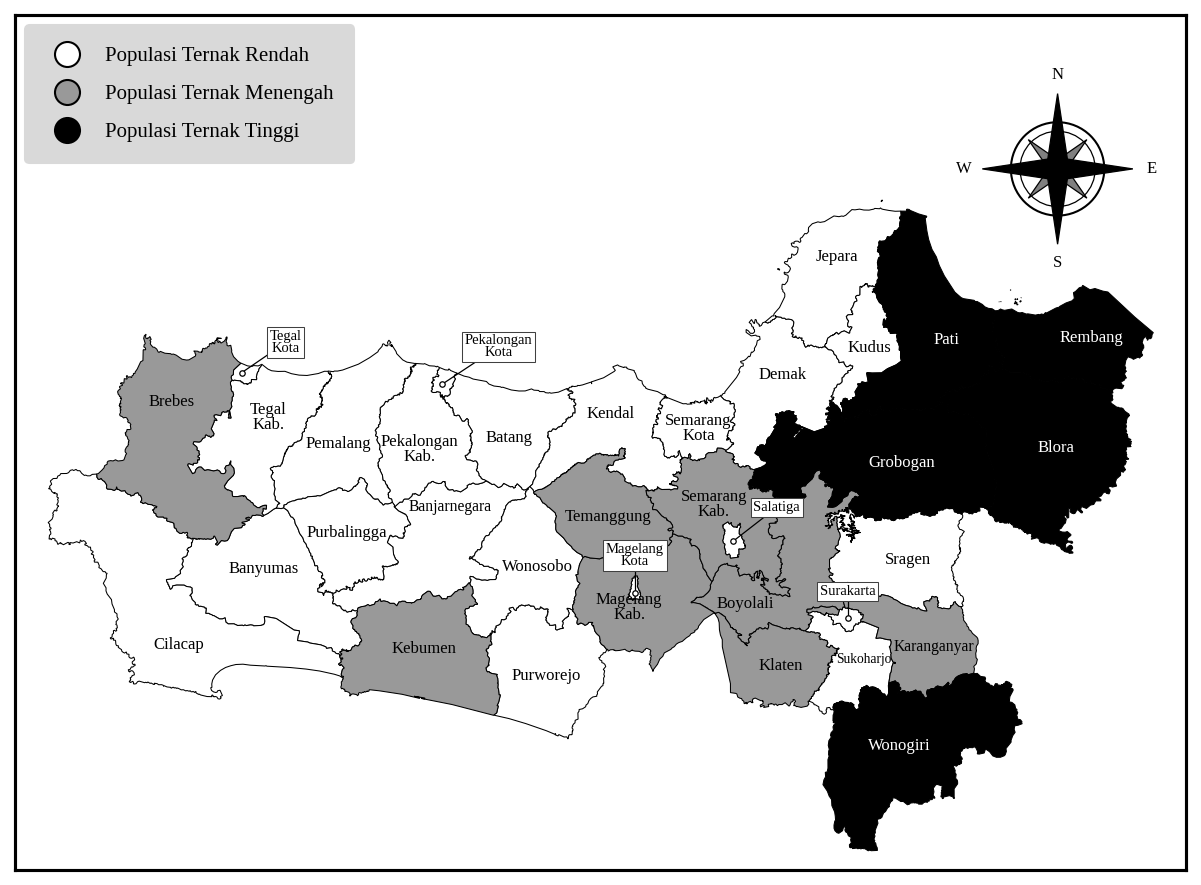

Peta Hasil Clustering Jarak Manhattan


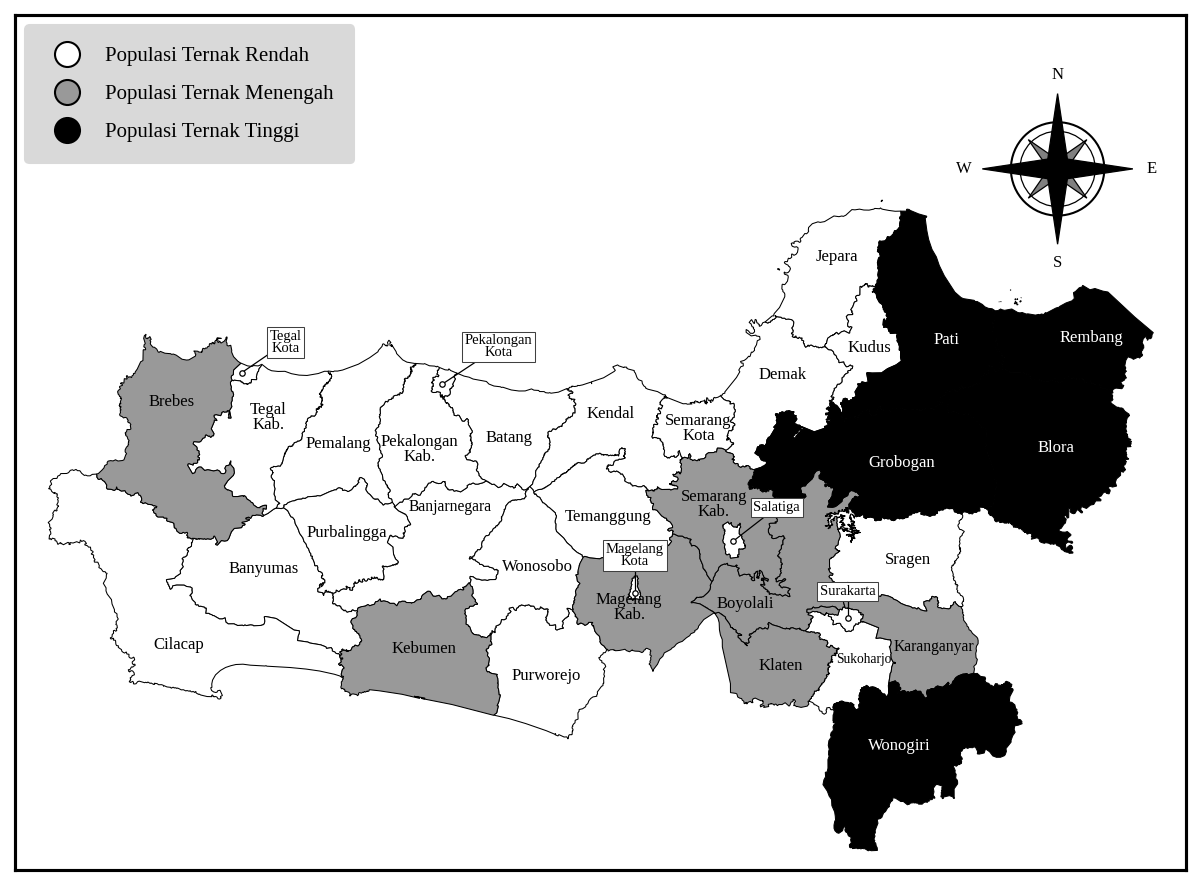

Peta Hasil Clustering Jarak Chebyshev


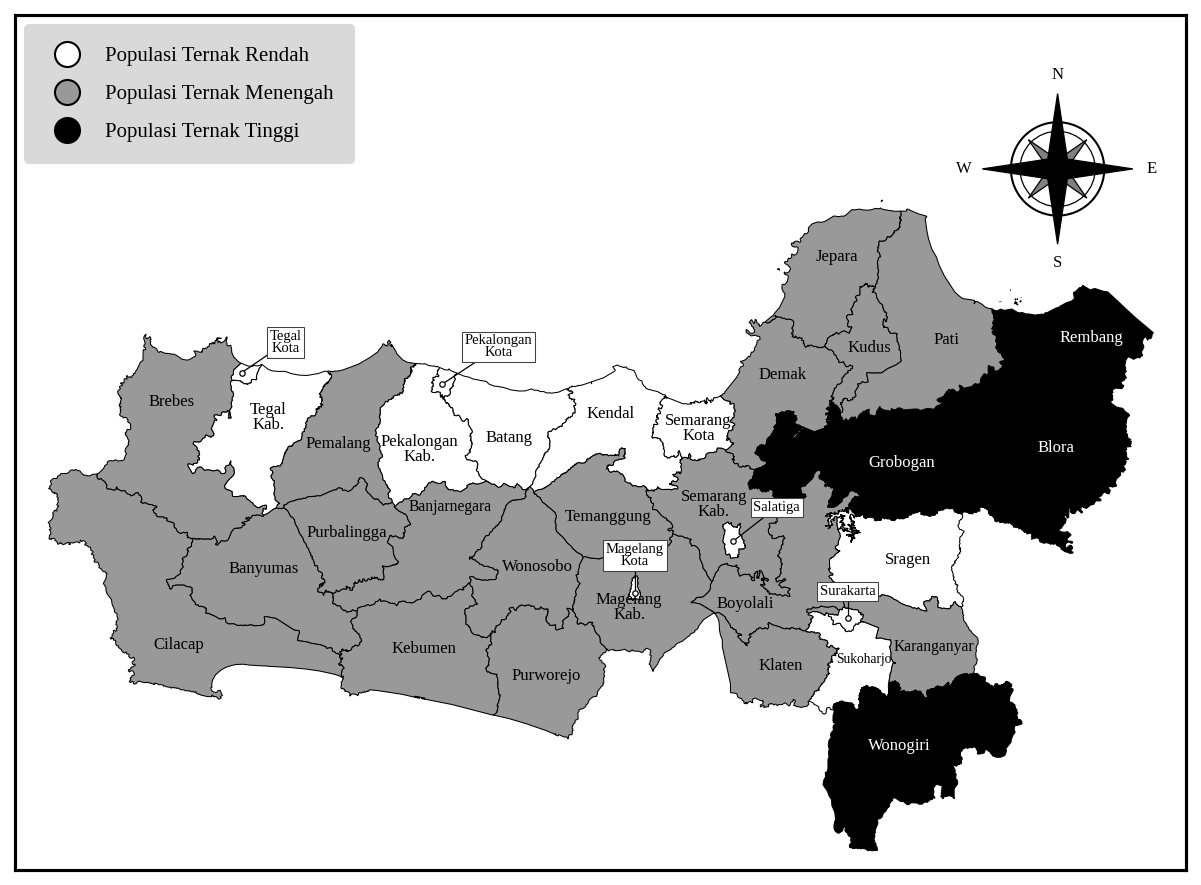

In [ ]:
# Mendefinisikan TINGKAT_CLUSTER
TINGKAT_CLUSTER = {1: 0, 2: 1, 3: 2}
# Menampilkan peta hasil clustering untuk setiap ukuran jarak
for label in hasil_std:
    print(f"Peta Hasil Clustering Jarak {label}")
    gambar_peta(label)